In [1]:
import numpy as np
import matplotlib.pyplot as plt
from src.fd_fxlms_offline import OfflineFxLMS
from src.measure_ir import *

In [2]:
data = np.load('./data/poster_normal_irs.npz')

error_learning = data['error_learning']
ref_learning = data['ref_learning']

error_frozen = data['error_frozen']
ref_frozen = data['ref_frozen']

error_foam = data['error_foam']
ref_foam = data['ref_foam']

error_opt_frozen = data['error_opt_frozen']
ref_opt_frozen = data['ref_opt_frozen']

error_opt_learning = data['error_opt_learning']
ref_opt_learning = data['ref_opt_learning']

cancel_gain_opt = data['cancel_gain_opt']
weights_from_opt = data['weights_from_opt']
w_norm_from_opt = data['w_norm_from_opt']

error_nc = data['error_nc']
ref_nc = data['ref_nc']
source = data['source']

error_ir = data['error_ir']
ref_ir = data['ref_ir']
error_ir_raw = data['error_ir_raw']
ref_ir_raw = data['ref_ir_raw']

learned_weights = data['learned_weights']
w_norm_log = data['w_norm_log']
w_norm = data['w_norm']

w_ls = data['w_ls']

n_repeats = int(data['n_repeats'])
fs = int(data['fs'])
ir_len = int(data['ir_len'])
panel_to_err_cm = float(data['panel_to_err_cm'])

mu = float(data['mu'])
leak = float(data['leak'])
eps = float(data['eps'])
lag = int(data['lag'])
cancel_gain = float(data['cancel_gain'])
ref_threshold = float(data['ref_threshold'])
mavg_tau_ms = float(data['mavg_tau_ms'])
update_sign = float(data['update_sign'])

In [5]:
def trim(n_iter, ref_arr=ref_nc, error_arr=error_nc, fs=fs):
    samples = int(n_iter * 5 * fs)
    return ref_arr[:samples], error_arr[:samples]

In [3]:
fx = OfflineFxLMS(
    M=1024,
    error_ir=error_ir,
    ref_ir=ref_ir,
    fs=96000,
    adaptation_mode="frequency",
    fd_block_size=128,
    fd_spectral_norm=False,
)

fx.set(
    mu=mu,
    leak=leak,
    eps=eps,
    lag=lag,
    cancel_gain=cancel_gain,
    ref_threshold=ref_threshold,
    mavg_tau_ms=mavg_tau_ms,
    update_sign=update_sign
)

Simulated ANC / No ANC: -7.16 dB


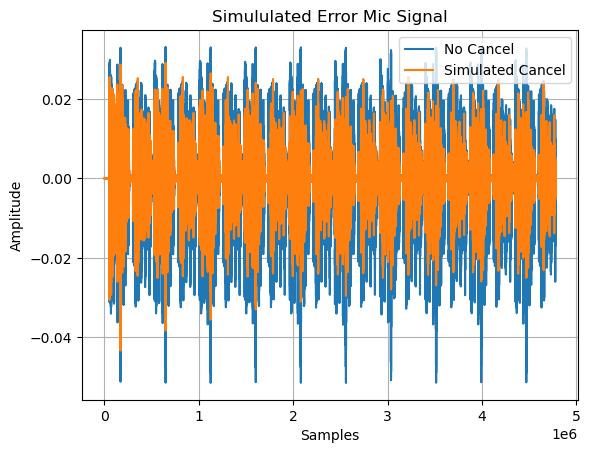

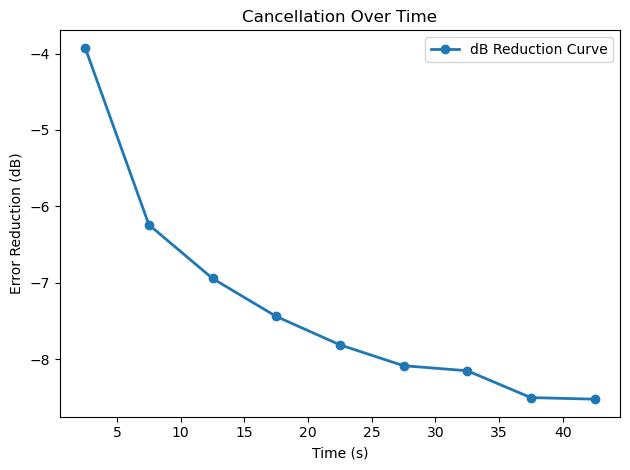

In [30]:
fx.reset()
control, error, panel_output, weights = fx.process_array(
    *trim(10),
    adapt=True,
    save_weight_every_s=0.5,
    plot=True,
    mu=.9,
    leak=1e-7,
    adaptation_mode='frequency',
    fd_spectral_norm=False,
    
)


Simulated ANC / No ANC: -2.51 dB


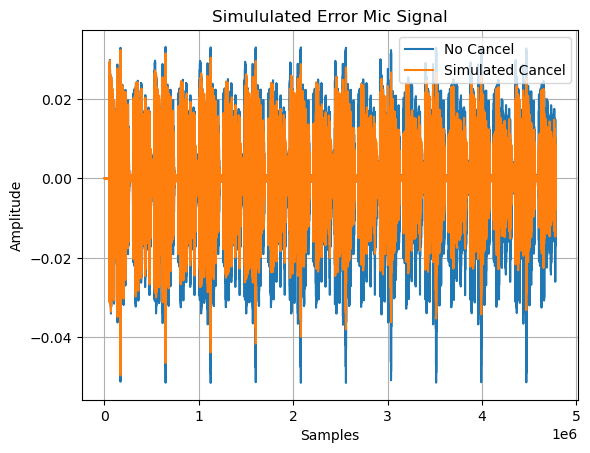

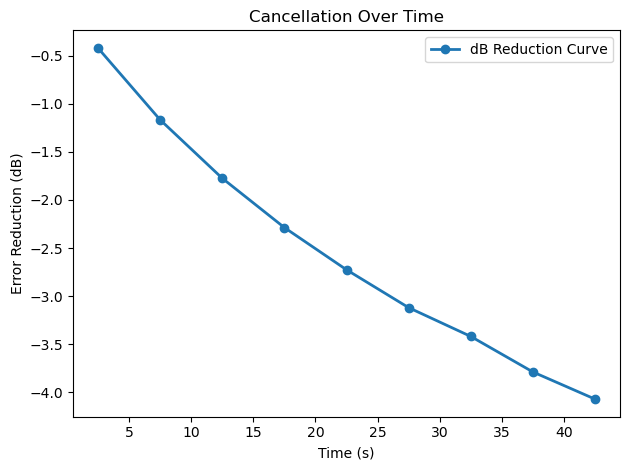

In [31]:
fx.reset()
control_f, error_f, panel_output_f, weights_f = fx.process_array(
    *trim(10),
    adapt=True,
    mu=.9,
    save_weight_every_s=0.5,
    fd_spectral_norm=True,
    adaptation_mode='frequency',
    plot=True
)


Simulated ANC / No ANC: -8.81 dB


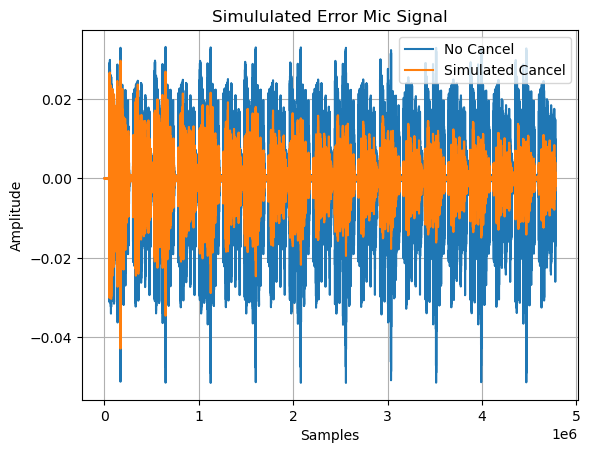

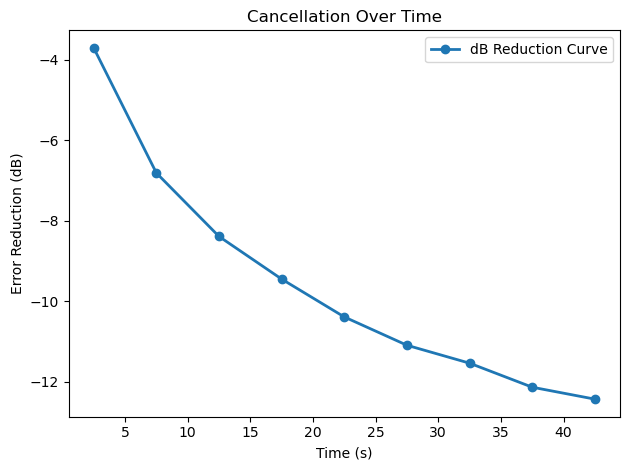

In [ ]:
fx.reset()
control_t, error_t, panel_output_t, weights_t = fx.process_array(
    *trim(10),
    adapt=True,
    mu=3e-3,
    save_weight_every_s=0.5,
    adaptation_mode='time',
    plot=True
)


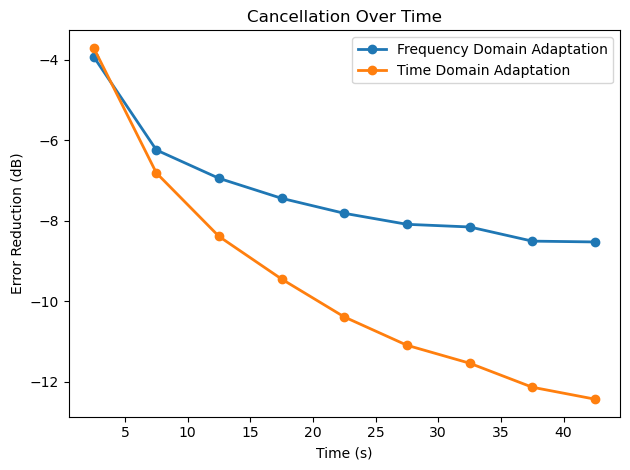

In [36]:
N = min(len(error), len(error_nc))

win = int(5.0 * fs)

t = []
loss = []
loss_t = []
loss_f = []

for start in range(0, N - win + 1, win):
    end = start + win

    loss.append(fx.reduction_db(error[start:end], error_nc[start:end]))
    loss_t.append(fx.reduction_db(error_t[start:end], error_nc[start:end]))
    loss_f.append(fx.reduction_db(error_f[start:end], error_nc[start:end]))


    # center of window
    t.append((start + win / 2) / fs)

plt.plot(t, loss, linewidth=2, label="Frequency Domain Adaptation", marker='o')
plt.plot(t, loss_t, linewidth=2, label="Time Domain Adaptation", marker='o')

plt.xlabel("Time (s)")
plt.ylabel("Error Reduction (dB)")
plt.title("Cancellation Over Time")

plt.legend()
plt.tight_layout()
plt.show()